# 02 · RFM segmentation

**Goal:** group customers by how **r**ecently, how **f**requently and how much (**m**onetary) they buy, so that each group can get its own retention action.

There are two complementary approaches:
- **Rule-based RFM scores.** These are transparent and standard in marketing, but the thresholds are fixed quintiles.
- **K-Means.** The group boundaries come from the data. The result is checked against the rule-based segments.

Input: the clean tables from `01` (`transactions`, `adjustments`).

In [1]:
import sys
from datetime import timedelta
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import polars as pl
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from src.config import ADJUSTMENTS, RANDOM_STATE, SEGMENTS, TRANSACTIONS
from src.features import rfm_scores, rfm_table
from src.plotting import (INK, INK_SECONDARY, NEUTRAL, SEGMENT_COLORS, SEGMENT_ORDER, SEQUENTIAL_CMAP,
                          save_fig, set_style)

set_style()
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(200)
transactions = pl.read_parquet(TRANSACTIONS)
adjustments = pl.read_parquet(ADJUSTMENTS)

## 1. RFM table

- **Snapshot date:** the day after the last transaction in the data. It is the same for every customer.
- **Recency:** days from the snapshot to the customer's last purchase day.
- **Frequency:** number of distinct orders (invoices).
- **Monetary:** net revenue (sales plus adjustments, £). Customers with net revenue ≤ 0 are left out, as decided in `01`.

`rfm_table()` lives in `src/features.py`, because `04` reuses it at a cutoff date.

In [2]:
SNAPSHOT = (transactions["invoice_date"].max() + timedelta(days=1)).date()
rfm = rfm_table(transactions, adjustments, SNAPSHOT)
print(f"Snapshot: {SNAPSHOT} | customers: {rfm.height:,}")

RFM = ["recency", "frequency", "monetary"]
pl.DataFrame({
    "statistic": ["25%", "median", "75%", "max"],
    **{col: [rfm[col].quantile(q) for q in (0.25, 0.5, 0.75)] + [rfm[col].max()] for col in RFM},
}).with_columns(pl.col("monetary").round(0))

Snapshot: 2011-12-10 | customers: 5,826


statistic,recency,frequency,monetary
str,f64,f64,f64
"""25%""",26.0,1.0,334.0
"""median""",96.0,3.0,842.0
"""75%""",379.0,7.0,2172.0
"""max""",739.0,369.0,570381.0


## 2. What do R, F and M look like?

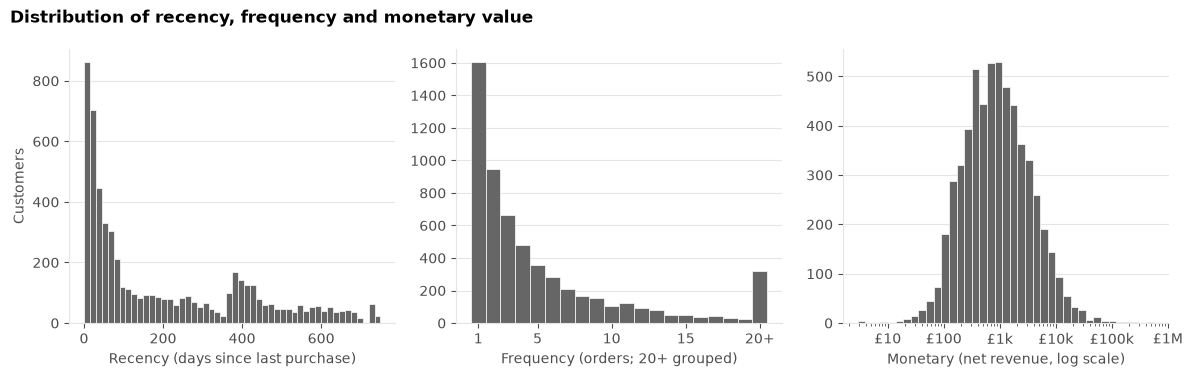

In [3]:
def compact_gbp(x, _):
    if x >= 1e6:
        return f"£{x / 1e6:g}M"
    return f"£{x / 1e3:g}k" if x >= 1e3 else f"£{x:g}"


MAX_ORDERS = 20
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

axes[0].hist(rfm["recency"], bins=np.arange(0, rfm["recency"].max() + 15, 15), color=NEUTRAL,
             edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Recency (days since last purchase)")

axes[1].hist(rfm["frequency"].clip(upper_bound=MAX_ORDERS), bins=np.arange(0.5, MAX_ORDERS + 1.5, 1),
             color=NEUTRAL, edgecolor="white", linewidth=0.5)
axes[1].set_xticks([1, 5, 10, 15, 20], ["1", "5", "10", "15", f"{MAX_ORDERS}+"])
axes[1].set_xlabel(f"Frequency (orders; {MAX_ORDERS}+ grouped)")

money_bins = np.logspace(np.log10(rfm["monetary"].min()), np.log10(rfm["monetary"].max()), 40)
axes[2].hist(rfm["monetary"], bins=money_bins, color=NEUTRAL, edgecolor="white", linewidth=0.5)
axes[2].set_xscale("log")
axes[2].xaxis.set_major_formatter(mtick.FuncFormatter(compact_gbp))
axes[2].set_xlabel("Monetary (net revenue, log scale)")

axes[0].set_ylabel("Customers")
fig.suptitle("Distribution of recency, frequency and monetary value", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_rfm_distributions")
plt.show()

In [4]:
pl.DataFrame({
    "variable": RFM,
    "skewness_raw": [stats.skew(rfm[col].to_numpy()) for col in RFM],
    "skewness_log1p": [stats.skew(np.log1p(rfm[col].to_numpy())) for col in RFM],
}).with_columns(pl.col("skewness_raw", "skewness_log1p").round(2))

variable,skewness_raw,skewness_log1p
str,f64,f64
"""recency""",0.9,-0.44
"""frequency""",11.95,1.0
"""monetary""",26.69,0.27


**Findings: distributions**

- **Frequency and monetary are extremely right-skewed.** A handful of customers have hundreds of orders or six-figure spend. Without a transform, they would dominate the K-Means distances.
- **log1p makes monetary close to symmetric.** Frequency stays moderately skewed, because more than a quarter of customers have exactly one order. Recency is only moderately skewed, and after log1p it leans slightly the other way, which is acceptable.

## 3. How are R, F and M related?

K-Means uses Euclidean distance, so two variables that measure the same thing count twice. Spearman correlation is used because the variables are skewed and the relationships are monotonic rather than linear.

In [5]:
spearman = stats.spearmanr(rfm.select(RFM).to_numpy()).statistic
pl.DataFrame({"variable": RFM, **{col: spearman[:, i].round(2) for i, col in enumerate(RFM)}})

variable,recency,frequency,monetary
str,f64,f64,f64
"""recency""",1.0,-0.56,-0.51
"""frequency""",-0.56,1.0,0.86
"""monetary""",-0.51,0.86,1.0


PCA on log1p R, F and M (standardised) shows how many independent directions the data really has.

In [6]:
Z = StandardScaler().fit_transform(np.log1p(rfm.select(RFM).to_numpy()))
pca = PCA(random_state=RANDOM_STATE).fit(Z)

# Orient the components so that higher PC1 = more valuable, higher PC2 = longer since last purchase
signs = np.sign([pca.components_[0, 2], pca.components_[1, 0], 1.0])
pl.DataFrame({
    "component": ["PC1", "PC2", "PC3"],
    "explained_variance": pca.explained_variance_ratio_.round(3),
    **{f"loading_{col}": (pca.components_ * signs[:, None])[:, i].round(2) for i, col in enumerate(RFM)},
})

component,explained_variance,loading_recency,loading_frequency,loading_monetary
str,f64,f64,f64,f64
"""PC1""",0.765,-0.5,0.62,0.6
"""PC2""",0.187,0.86,0.3,0.41
"""PC3""",0.048,0.07,0.73,-0.68


**Findings: relationships**

- **Frequency and monetary move together.** Customers who order more often spend more. Recency is negatively related to both: frequent buyers also bought recently.
- **The data has essentially two directions.** PC1, about three quarters of the variance, is customer value: more orders, more spend, more recent. PC2 is mostly time since the last purchase. PC3 contrasts frequency with spend, that is, order size, and adds little.
- **Consequence:** F and M measure the same thing, value. Clustering on all three variables would count value twice, so section 4 combines F and M into a single value score.

## 4. K-Means

### 4.1 Features

Frequency and monetary carry the same information, so they are combined into a single **value** score: the mean of their standardised logs. K-Means then uses two features with equal weight:
- **recency:** log1p of days, standardised.
- **value:** standardised.

Clustering directly on the three standardised variables would give F and M together twice the weight of recency. Section 4.3 measures how much that changes the result.

In [7]:
value = Z[:, 1:].mean(axis=1)
X = StandardScaler().fit_transform(np.column_stack([Z[:, 0], value]))
rfm = rfm.with_columns(recency_z=X[:, 0], value_z=X[:, 1])

### 4.2 Number of clusters

**Criterion:**
- k must be between 3 and 6, because fewer groups are not actionable and more are hard to run as campaigns.
- The partition must be stable under resampling: the median adjusted Rand index (ARI) between the full-data clusters and clusters fitted on 20 bootstrap samples must be ≥ 0.9.
- The smallest cluster must hold at least 5% of customers.
- Among the k that pass, take the highest mean silhouette.

The table also shows the minimum ARI across 5 random seeds, which checks that the optimiser converges to the same solution.

In [8]:
K_RANGE = range(2, 9)
SEEDS = [1, 2, 3, 4, 5]
N_BOOTSTRAP = 20
rng = np.random.default_rng(RANDOM_STATE)


def kmeans(k, seed=RANDOM_STATE):
    return KMeans(n_clusters=k, n_init=10, random_state=seed)


rows = []
for k in K_RANGE:
    fitted = kmeans(k).fit(X)
    bootstrap_ari = [
        adjusted_rand_score(fitted.labels_, kmeans(k).fit(X[rng.integers(0, len(X), len(X))]).predict(X))
        for _ in range(N_BOOTSTRAP)
    ]
    rows.append({
        "k": k,
        "inertia": fitted.inertia_,
        "silhouette": silhouette_score(X, fitted.labels_),
        "bootstrap_ari_median": np.median(bootstrap_ari),
        "bootstrap_ari_min": np.min(bootstrap_ari),
        "seed_ari_min": min(adjusted_rand_score(fitted.labels_, kmeans(k, seed).fit_predict(X)) for seed in SEEDS),
        "smallest_cluster_pct": np.bincount(fitted.labels_).min() / len(X) * 100,
    })
k_table = pl.DataFrame(rows).with_columns(pl.exclude("k").round(3))
k_table

k,inertia,silhouette,bootstrap_ari_median,bootstrap_ari_min,seed_ari_min,smallest_cluster_pct
i64,f64,f64,f64,f64,f64,f64
2,5395.422,0.464,0.981,0.911,0.995,42.207
3,3843.537,0.405,0.952,0.884,0.989,23.086
4,2825.068,0.414,0.938,0.874,0.979,18.95
5,2317.304,0.384,0.97,0.513,0.982,11.517
6,1882.695,0.396,0.959,0.89,0.965,7.552
7,1676.51,0.372,0.705,0.642,0.67,5.338
8,1478.244,0.383,0.821,0.644,0.708,4.411


Chosen k: 4


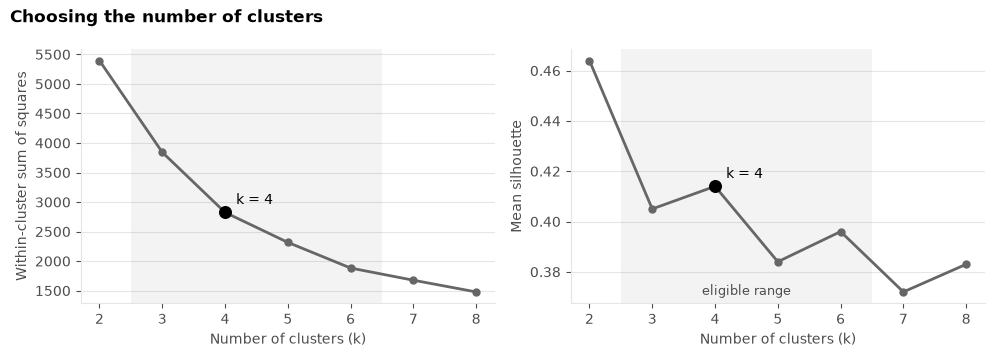

In [9]:
eligible = k_table.filter(
    pl.col("k").is_between(3, 6), pl.col("bootstrap_ari_median") >= 0.9, pl.col("smallest_cluster_pct") >= 5
)
K = eligible.sort("silhouette", descending=True)["k"][0]
print(f"Chosen k: {K}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, label in [(axes[0], "inertia", "Within-cluster sum of squares"), (axes[1], "silhouette", "Mean silhouette")]:
    ax.plot(k_table["k"], k_table[col], marker="o", markersize=5, color=NEUTRAL)
    chosen = k_table.filter(pl.col("k") == K)[col].item()
    ax.scatter([K], [chosen], s=70, color=INK, zorder=3)
    ax.annotate(f"k = {K}", (K, chosen), xytext=(8, 6), textcoords="offset points", color=INK)
    ax.axvspan(2.5, 6.5, color=NEUTRAL, alpha=0.08, linewidth=0)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel(label)
axes[1].annotate("eligible range", (4.5, axes[1].get_ylim()[0]), xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", color=INK_SECONDARY, fontsize=9)
fig.suptitle("Choosing the number of clusters", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_choosing_k")
plt.show()

### 4.3 Does the feature weighting matter?

The chosen model is compared with K-Means on the three standardised variables, where F and M together weigh twice as much as recency, at the same k.

In [10]:
model = kmeans(K).fit(X)
labels_three_features = kmeans(K).fit_predict(Z)
print(f"Agreement with K-Means on standardised R, F, M (ARI): {adjusted_rand_score(model.labels_, labels_three_features):.2f}")

# ARI is not a share of customers: match the clusters one to one, then count who moves
overlap = np.zeros((K, K), dtype=int)
np.add.at(overlap, (model.labels_, labels_three_features), 1)
rows, cols = linear_sum_assignment(-overlap)
print(f"Customers who change segment after matching the clusters: {1 - overlap[rows, cols].sum() / len(X):.0%}")


def recent_buyers_in_oldest_cluster(labels):
    # Share of the cluster with the longest median recency that bought in the last 90 days
    df = rfm.select("recency").with_columns(cluster=pl.Series(labels))
    oldest = df.group_by("cluster").agg(pl.col("recency").median()).sort("recency")["cluster"][-1]
    return (df.filter(pl.col("cluster") == oldest)["recency"] <= 90).mean()


print(f"Customers who bought in the last 90 days inside the 'oldest' cluster: "
      f"{recent_buyers_in_oldest_cluster(model.labels_):.0%} with recency + value, "
      f"{recent_buyers_in_oldest_cluster(labels_three_features):.0%} with R, F, M")

Agreement with K-Means on standardised R, F, M (ARI): 0.76
Customers who change segment after matching the clusters: 10%
Customers who bought in the last 90 days inside the 'oldest' cluster: 1% with recency + value, 7% with R, F, M


**Findings: K-Means**

- **k = 4 is chosen by the criterion.** It has the highest silhouette in the 3–6 range, it is stable under bootstrap resampling, and its smallest cluster is almost a fifth of the customers. k = 2 scores higher, but two groups are too coarse for targeted actions.
- **The silhouette is moderate.** The segments are regions of a continuum, not well-separated groups, so customers near a border could fall either way (see the map in 5.2).
- **The weighting matters, moderately.** Compared with clustering on R, F and M directly, about one customer in ten changes segment. With value counted twice, 7% of the "oldest" cluster bought in the last 90 days, against 1% with equal weights. Equal weights let recency and value both shape the segments, which is what retention actions need.

## 5. Segment profiles

The cluster numbers are arbitrary, so each cluster is named from its median profile, using explicit rules:
- **Champions:** the cluster with the highest median value.
- **Lost:** of the rest, the one with the longest median recency.
- **Promising:** of the rest, the one with the shortest median recency.
- **At risk:** the remaining cluster.

The assertions check properties that the naming rules do not guarantee by construction, so the notebook stops if a profile no longer fits its name.

In [11]:
rfm = rfm.with_columns(cluster=pl.Series(model.labels_))
medians = rfm.group_by("cluster").agg(pl.col("recency", "value_z").median())

champions = medians.sort("value_z")["cluster"][-1]
rest = medians.filter(pl.col("cluster") != champions).sort("recency")
lost, promising = rest["cluster"][-1], rest["cluster"][0]
at_risk = rest.filter(~pl.col("cluster").is_in([lost, promising]))["cluster"][0]
names = {champions: "Champions", promising: "Promising", at_risk: "At risk", lost: "Lost"}
assert len(names) == K == len(SEGMENT_ORDER)

first_purchase = transactions.group_by("customer_id").agg(first_purchase=pl.col("invoice_date").min().dt.date())
rfm = rfm.with_columns(segment=pl.col("cluster").replace_strict(names)).join(first_purchase, on="customer_id")

m = {row["segment"]: row for row in rfm.group_by("segment").agg(pl.col(RFM).median()).iter_rows(named=True)}
assert all(m["Champions"][col] >= m[s][col] for s in SEGMENT_ORDER for col in ["frequency", "monetary"])
assert m["Promising"]["monetary"] < m["At risk"]["monetary"]  # recent but not yet valuable
assert m["Lost"]["recency"] > 365  # typical Lost customer has not bought for over a year

segment_rank = {s: i for i, s in enumerate(SEGMENT_ORDER)}
profile = (
    rfm.group_by("segment")
    .agg(
        customers=pl.len(),
        recency_p25=pl.col("recency").quantile(0.25),
        recency_median=pl.col("recency").median(),
        recency_p75=pl.col("recency").quantile(0.75),
        pct_bought_last_90d=(pl.col("recency") <= 90).mean() * 100,
        pct_inactive_over_1y=(pl.col("recency") > 365).mean() * 100,
        median_orders=pl.col("frequency").median(),
        median_net_revenue=pl.col("monetary").median(),
        median_order_value=pl.col("avg_order_value").median(),
        pct_first_order_last_90d=((SNAPSHOT - pl.col("first_purchase")).dt.total_days() <= 90).mean() * 100,
        revenue=pl.col("monetary").sum(),
    )
    .with_columns(
        pct_customers=pl.col("customers") / pl.col("customers").sum() * 100,
        pct_revenue=pl.col("revenue") / pl.col("revenue").sum() * 100,
    )
    .drop("revenue")
    .with_columns(pl.selectors.float().round(0))
    .sort(pl.col("segment").replace_strict(segment_rank))
)
profile

segment,customers,recency_p25,recency_median,recency_p75,pct_bought_last_90d,pct_inactive_over_1y,median_orders,median_net_revenue,median_order_value,pct_first_order_last_90d,pct_customers,pct_revenue
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Champions""",1104,5.0,12.0,25.0,100.0,0.0,13.0,4481.0,347.0,2.0,19.0,69.0
"""Promising""",1321,16.0,29.0,51.0,99.0,0.0,2.0,624.0,241.0,41.0,23.0,6.0
"""At risk""",1331,78.0,137.0,256.0,33.0,16.0,5.0,1740.0,324.0,0.0,23.0,20.0
"""Lost""",2070,282.0,409.0,544.0,1.0,66.0,1.0,308.0,208.0,1.0,36.0,5.0


### 5.1 How do the segments differ in R, F and M?

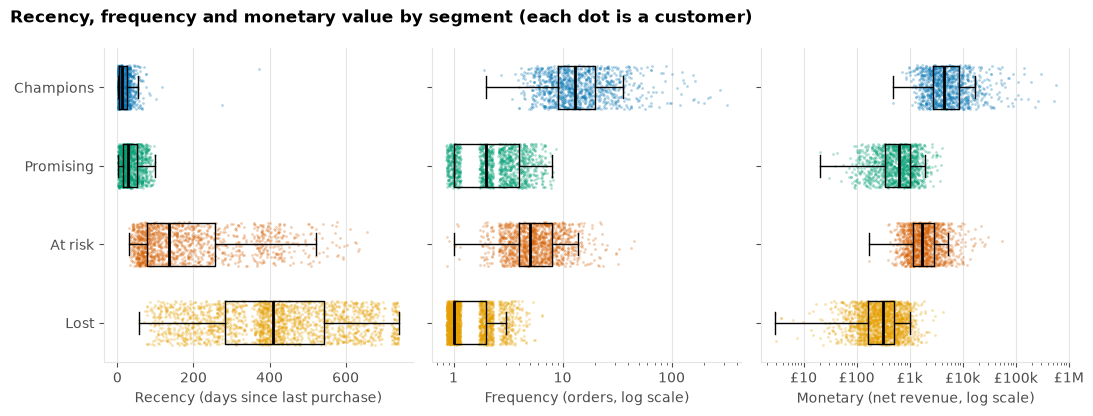

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2), sharey=True)
panels = [("recency", "Recency (days since last purchase)", False),
          ("frequency", "Frequency (orders, log scale)", True),
          ("monetary", "Monetary (net revenue, log scale)", True)]

for ax, (col, label, log) in zip(axes, panels):
    data = [rfm.filter(pl.col("segment") == s)[col].to_numpy() for s in SEGMENT_ORDER]
    for i, (segment, values) in enumerate(zip(SEGMENT_ORDER, data)):
        jitter = rng.uniform(-0.28, 0.28, len(values))
        x = values * np.exp(rng.uniform(-0.15, 0.15, len(values))) if col == "frequency" else values
        ax.scatter(x, i + jitter, s=4, alpha=0.3, color=SEGMENT_COLORS[segment], linewidths=0, rasterized=True)
    ax.boxplot(data, positions=range(len(SEGMENT_ORDER)), widths=0.55, showfliers=False, orientation="horizontal",
               medianprops={"color": INK, "linewidth": 2}, boxprops={"color": INK}, whiskerprops={"color": INK},
               capprops={"color": INK})
    if log:
        ax.set_xscale("log")
    formatter = compact_gbp if col == "monetary" else (lambda v, _: f"{v:,.0f}")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(formatter))
    ax.set_xlabel(label)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(SEGMENT_ORDER)), SEGMENT_ORDER)
axes[0].invert_yaxis()
fig.suptitle("Recency, frequency and monetary value by segment (each dot is a customer)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_segment_profiles")
plt.show()

Frequency is a whole number, so its dots get a small horizontal jitter to show how many customers sit on each value. The boxes are computed on the exact values. The dots also act as the bimodality check that a boxplot alone would hide.

### 5.2 Where are the borders between segments?

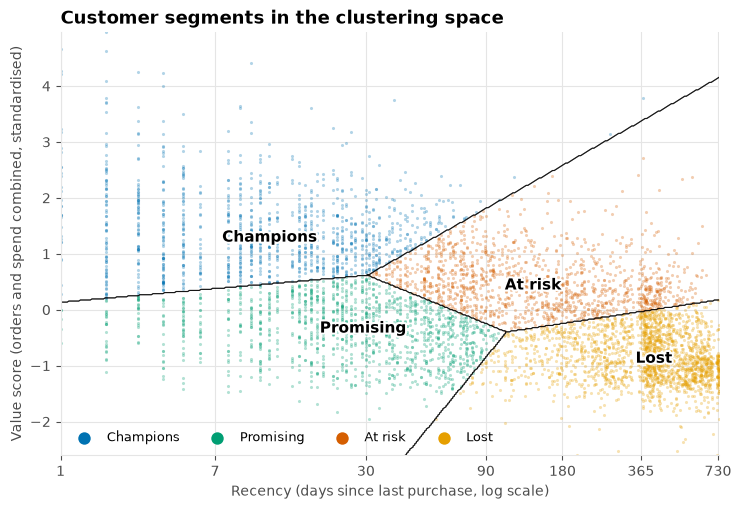

In [13]:
DAY_TICKS = [1, 7, 30, 90, 180, 365, 730]
log_recency = np.log1p(rfm["recency"].to_numpy())


def days_to_axis(days):
    """Same scaling as recency_z, so the x ticks can show days."""
    return (np.log1p(days) - log_recency.mean()) / log_recency.std()


fig, ax = plt.subplots(figsize=(8.5, 5.5))
for segment in SEGMENT_ORDER:
    part = rfm.filter(pl.col("segment") == segment)
    ax.scatter(part["recency_z"], part["value_z"], s=5, alpha=0.3, color=SEGMENT_COLORS[segment], linewidths=0,
               label=segment, rasterized=True)
    ax.annotate(segment, (part["recency_z"].median(), part["value_z"].median()), ha="center", va="center",
                fontsize=11, fontweight="bold", color=INK, path_effects=[pe.withStroke(linewidth=3, foreground="white")])
# K-Means borders, so the segments can be told apart without colour (print, colour blindness)
gx, gy = np.meshgrid(np.linspace(X[:, 0].min(), X[:, 0].max(), 400), np.linspace(X[:, 1].min(), X[:, 1].max(), 400))
grid = model.predict(np.column_stack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
for cluster in range(K):
    ax.contour(gx, gy, (grid == cluster).astype(float), levels=[0.5], colors=INK, linewidths=0.8, alpha=0.7)
ax.set_xticks(days_to_axis(np.array(DAY_TICKS)), [str(d) for d in DAY_TICKS])
ax.set_xlabel("Recency (days since last purchase, log scale)")
ax.set_ylabel("Value score (orders and spend combined, standardised)")
ax.set_title("Customer segments in the clustering space")
ax.grid(axis="x")
legend = ax.legend(markerscale=4, loc="lower left", ncols=4, fontsize=9)
for handle in legend.legend_handles:
    handle.set_alpha(1)
save_fig(fig, "02_segments_map")
plt.show()

In [14]:
# The vertical edge near 365 days: when did these customers last buy?
last_purchase = rfm.with_columns(last_purchase=pl.lit(SNAPSHOT) - pl.duration(days=pl.col("recency")))
year_ago = last_purchase.filter(pl.col("recency").is_between(330, 450))
print(f"Customers whose last purchase was 330-450 days ago: {year_ago.height:,}, of which "
      f"{year_ago['last_purchase'].dt.month().is_in([9, 10, 11, 12]).mean():.0%} last bought in Sep-Dec 2010 (the 2010 peak)")

Customers whose last purchase was 330-450 days ago: 804, of which 96% last bought in Sep-Dec 2010 (the 2010 peak)


### 5.3 How big is each segment, and how much revenue does it bring?

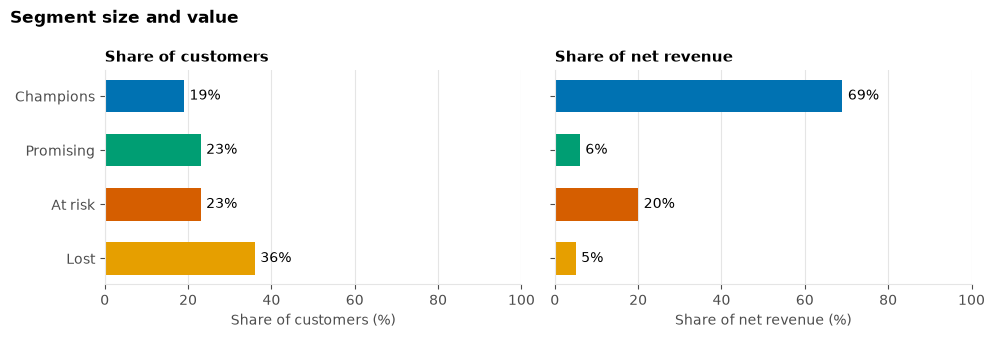

In [15]:
order = SEGMENT_ORDER[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, col, title in [(axes[0], "pct_customers", "Share of customers"), (axes[1], "pct_revenue", "Share of net revenue")]:
    values = [profile.filter(pl.col("segment") == s)[col].item() for s in order]
    ax.barh(order, values, color=[SEGMENT_COLORS[s] for s in order], height=0.6)
    for y, v in enumerate(values):
        ax.annotate(f"{v:.0f}%", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK)
    ax.set_xlim(0, 100)
    ax.set_xlabel(f"{title} (%)")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
fig.suptitle("Segment size and value", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_segment_size_value")
plt.show()

**Findings: segments**

- **Champions:** about a fifth of the customers bring about 70% of net revenue. Virtually all of them bought in the last 90 days, and they order often.
- **Promising:** recent buyers with few orders and low spend so far. About 40% placed their first order in the last 90 days, so many of them are new customers.
- **At risk:** mid-value buyers with several orders whose last order was typically about four and a half months ago, with a wide spread: a third bought in the last 90 days. They bring about a fifth of the revenue, so they are the main retention target. Whether they are actually slowing down is a question for the churn model in `04`.
- **Lost:** a third of the customers, mostly with a single small order. Two thirds have not bought for over a year, and they bring little revenue. The sharp edge near 365 days in the map is seasonal: almost all the customers whose last order was about a year ago bought during the 2010 Christmas peak and never came back.
- The order value differs less between segments than frequency does. What separates customers is mainly how often they come back.

## 6. Do the clusters agree with rule-based RFM segments?

Each customer gets 1–5 scores for R, F and M from their percentile rank (`rfm_scores()` in `src/features.py`, 5 = best). The rule-based segment uses the recency score and the combined frequency-monetary score:

| Rule segment | Recency score | Frequency-monetary score |
|---|---|---|
| Champions | 4–5 | 4–5 |
| Promising | 4–5 | 1–3 |
| Needs attention | 3 | any |
| At risk | 1–2 | 3–5 |
| Lost | 1–2 | 1–2 |

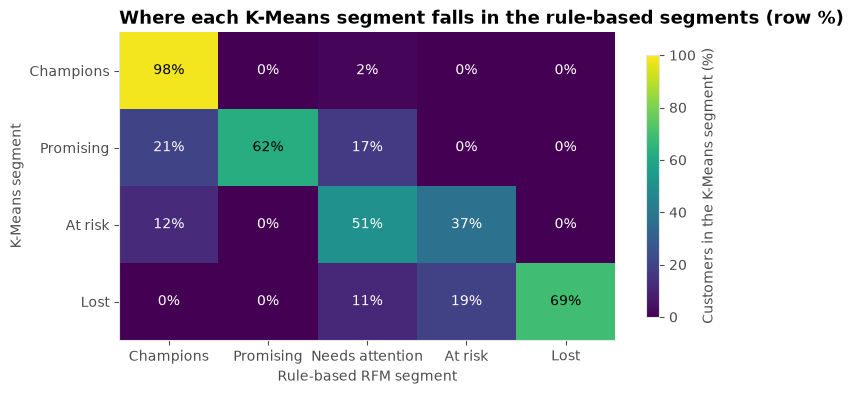

Adjusted Rand index, K-Means vs rule-based segments: 0.50


In [16]:
RULE_ORDER = ["Champions", "Promising", "Needs attention", "At risk", "Lost"]
rfm = rfm_scores(rfm)

counts = rfm.group_by("segment", "rfm_segment").len()
crosstab = (
    counts.with_columns(pct=pl.col("len") / pl.col("len").sum().over("segment") * 100)
    .pivot(on="rfm_segment", index="segment", values="pct")
    .fill_null(0)
    .sort(pl.col("segment").replace_strict(segment_rank))
    .select("segment", *RULE_ORDER)
)
matrix = crosstab.select(RULE_ORDER).to_numpy()

fig, ax = plt.subplots(figsize=(8, 4))
image = ax.imshow(matrix, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=100, aspect="auto")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, f"{matrix[i, j]:.0f}%", ha="center", va="center", fontsize=10,
                color="white" if matrix[i, j] < 60 else INK)
ax.set_xticks(range(len(RULE_ORDER)), RULE_ORDER)
ax.set_yticks(range(len(SEGMENT_ORDER)), SEGMENT_ORDER)
ax.set_xlabel("Rule-based RFM segment")
ax.set_ylabel("K-Means segment")
ax.set_title("Where each K-Means segment falls in the rule-based segments (row %)")
ax.grid(False)
fig.colorbar(image, ax=ax, label="Customers in the K-Means segment (%)", shrink=0.85)
save_fig(fig, "02_kmeans_vs_rules")
plt.show()

print(f"Adjusted Rand index, K-Means vs rule-based segments: {adjusted_rand_score(rfm['segment'], rfm['rfm_segment']):.2f}")

In [17]:
# Promising customers that the rules call Champions, compared with K-Means Champions
rfm.filter(
    (pl.col("segment") == "Champions") | ((pl.col("segment") == "Promising") & (pl.col("rfm_segment") == "Champions"))
).group_by(group=pl.when(pl.col("segment") == "Champions").then(pl.lit("K-Means Champions"))
          .otherwise(pl.lit("K-Means Promising that the rules call Champions"))).agg(
    customers=pl.len(), median_orders=pl.col("frequency").median(), median_net_revenue=pl.col("monetary").median().round(0)
).sort("median_orders")

group,customers,median_orders,median_net_revenue
str,u32,f64,f64
"""K-Means Promising that the rul…",273,5.0,1282.0
"""K-Means Champions""",1104,13.0,4481.0


In [18]:
# The other direction: where do the rule-based "Needs attention" customers end up?
counts.filter(pl.col("rfm_segment") == "Needs attention").with_columns(
    pct=(pl.col("len") / pl.col("len").sum() * 100).round(0)
).sort("len", descending=True)

segment,rfm_segment,len,pct
str,str,u32,f64
"""At risk""","""Needs attention""",673,58.0
"""Lost""","""Needs attention""",234,20.0
"""Promising""","""Needs attention""",226,20.0
"""Champions""","""Needs attention""",18,2.0


**Findings: K-Means vs rule-based RFM**

- **The two methods agree on the extremes.** Almost all K-Means Champions are rule-based Champions, and most Lost customers are rule-based Lost.
- **They differ in the middle.** Half of the K-Means At risk customers fall in the rule-based "Needs attention" group (recency score 3), and in the other direction most "Needs attention" customers end up in At risk. A fifth of K-Means Promising customers are rule-based Champions: recent and with a fairly high score, but with far fewer orders and much lower spend than the K-Means Champions. Also, 12% of K-Means At risk customers are rule-based Champions, which matches the wide recency spread of that segment.
- **K-Means segments are used from here on.** Their boundaries come from the data instead of fixed quintiles, and they weigh recency and value equally. The rules are easier to explain, so the scores stay in the table. This is a modelling choice, not a test result.

## 7. Save

In [19]:
rfm.select(
    "customer_id", *RFM, "avg_order_value", "recency_z", "value_z", "r_score", "f_score", "m_score", "fm_score",
    "rfm_segment", "segment",
).write_parquet(SEGMENTS)
print(f"Saved {rfm.height:,} customers to {SEGMENTS.name}")

Saved 5,826 customers to segments.parquet


## Summary

- **Output:** `data/processed/segments.parquet` has, for each customer, R, F, M, average order value, the recency and value scores used for clustering, the 1–5 scores, the rule-based segment and the K-Means segment.
- **Four segments:** Champions, Promising, At risk and Lost. Revenue is concentrated in Champions, with At risk second. Keeping both groups matters most.
- **Methodological decisions:**
  - log1p and standardisation.
  - F and M combined into one value score, after PCA showed they measure the same thing.
  - k chosen by a stated criterion that includes bootstrap stability.
  - Cluster names assigned by explicit rules, with assertions on the profiles.
- **Limitations:**
  - The segments are a snapshot at the end of the data, and their borders are soft (moderate silhouette).
  - F and M grow with tenure. Recently acquired customers (many of them in Promising) have not had time to place many orders, and customers from December 2009 have a history that starts before the data.
- **Next:** `03` measures retention by acquisition cohort. `04` predicts which customers will stop buying, which turns "At risk" from a snapshot into a forecast.